<a href="https://colab.research.google.com/github/alexlimatds/esp_introducao_am/blob/main/07_classificacao_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificação com Random Forest

O **Random Forest** (floresta aleatória) é um algoritmo de aprendizado de máquina supervisionado baseado em um conjunto (*ensemble*) de árvores de decisão. Em vez de confiar em uma única árvore, ele treina muitas árvores com variações aleatórias nos dados e nas variáveis e combina suas previsões, obtendo geralmente maior precisão e estabilidade do que uma árvore isolada.

![](https://assets.ibm.com/is/image/ibm/ICLH_Diagram_Batch_03_27-RandomForest:16x9?fmt=png-alpha&dpr=on%2C1&fit=fit%2C1&wid=1536&hei=864) \
Fonte: https://www.ibm.com/think/topics/random-forest

## Intuição do algoritmo

Uma árvore de decisão aprende regras do tipo “se a renda for alta e o histórico de crédito for bom, aprovar o empréstimo”. Esse modelo é fácil de interpretar, mas costuma ter **alta variância**: pequenas mudanças nos dados de treinamento podem gerar árvores bastante diferentes e, por isso, uma única árvore pode se ajustar demais (*overfitting*) aos exemplos específicos do conjunto de treino.

O Random Forest ataca esse problema criando uma “floresta” de árvores. Para classificação, cada árvore vota em uma classe e a mais votada é escolhida; para regressão, as previsões das árvores são médias.


## Bagging

O **bagging** (*bootstrap aggregating*) é a técnica que consiste em treinar vários modelos sobre amostras de dados geradas por *bootstrap*. Uma amostra bootstrap é criado sorteando instâncias do conjunto original **com reposição**: uma mesma instância pode aparecer mais de uma vez em uma amostra, enquanto outras podem não aparecer. Cerca de $\frac{1}{3}$ dos elementos de uma amostra bootstrap são instâncias duplicadas.

![](https://github.com/alexlimatds/esp_introducao_am/blob/main/imagens/bootstrap_rf.png?raw=true)

Cada árvore é treinada em uma dessas amostras, e suas previsões são agregadas por voto majoritário, no caso da classificação, ou pela média, no caso da regressão. A ideia central é reduzir a variância: se as árvores forem razoavelmente diversas e pouco correlacionadas, os erros individuais tendem a se compensar quando combinados.


## Seleção aleatória de atributos

O bagging sozinho pode produzir árvores parecidas quando existe uma variável com alto poder preditivo. Como todas as árvores tendem a escolhê-la nas primeiras divisões, elas permanecem correlacionadas e o ganho da média é reduzido. Para contornar esse problema, o Random Forest amplia o bagging com uma segunda fonte de aleatoriedade: **seleção aleatória de variáveis em cada divisão do nó**. Ao construir um nó, o algoritmo não avalia todas as variáveis, mas apenas um subconjunto aleatório de delas e escolhe a melhor divisão dentro desse subconjunto.

Essa restrição força árvores diferentes a explorar variáveis distintas, reduzindo a correlação entre elas. Em dados com uma variável dominante, por exemplo, algumas árvores serão construídas sem acesso a ela em determinada divisão e poderão descobrir padrões úteis em outras variáveis.

Assim, pode-se resumir o Random Forest como:

$$
\text{Random Forest} = \text{Bagging de árvores} + \text{amostragem aleatória de variáveis por nó}
$$


## Avaliação fora da amostra

Uma consequência do processo de amostragem por bootstrap é a possibilidade de realizar uma validação interna contínua sem a necessidade de separar explicitamente um conjunto de validação. Em média, cada árvore da floresta é treinada utilizando aproximadamente 63% das amostras únicas do conjunto original, deixando cerca de 37% das instâncias de fora. Essas observações excluídas do treinamento da árvore são denominadas amostras **Out-of-Bag** (OOB) para aquela árvore específica. Para calcular o erro OOB do modelo completo, o algoritmo percorre cada instância $x_i$ do conjunto de dados original e identifica apenas o subconjunto de árvores da floresta que não utilizaram $x_i$ durante o treinamento (o que corresponde, em média, a cerca de um terço das árvores). As previsões dessas árvores são então agregadas por votação majoritária para produzir a classificação OOB de $x_i$. Comparando as previsões OOB com os rótulos verdadeiros $y_i$ de todas as amostras, obtém-se uma estimativa não enviesada do erro de generalização do modelo, comportando-se de maneira muito semelhante à validação cruzada $k$-fold (k-fold cross-validation), porém integrada diretamente ao processo único de treinamento.

## Desempenho e sobreajuste

Esperamos que a precisão do treinamento e do teste de uma floresta aleatória seja diferente. A precisão de treinamento de uma floresta aleatória é geralmente muito maior (às vezes igual a 100%). No entanto, uma precisão de treinamento muito alta em uma floresta aleatória é normal e não indica que a floresta aleatória está superajustada.

As árvores de decisão individuais em uma floresta aleatória são treinadas sem poda. Isso produz árvores muito complexas com baixa qualidade preditiva.
As duas fontes de aleatoriedade (bagging e amostragem de atributos) garantem a independência relativa entre as árvores de decisão. Essa independência corrige o ajuste excessivo das árvores de decisão individuais e a floresta não se superajusta aos dados.

Florestas aleatórias puras são treinadas sem profundidade máxima ou número mínimo de observações por folha. Na prática, limitar a profundidade máxima e o número mínimo de observações por folha é benéfico. Por padrão, muitas florestas aleatórias usam os seguintes padrões:

- Profundidade máxima de ~16.
- Número mínimo de observações por folha de ~5.

Ao treinar uma floresta aleatória, conforme mais árvores de decisão são adicionadas, o erro quase sempre diminui. Ou seja, a qualidade do modelo quase sempre melhora e, ainda assim, o modelo não apresenta superajuste. No entanto, em algum momento o modelo para de melhorar.

Por exemplo, o gráfico a seguir mostra a avaliação de um modelo de floresta aleatória à medida que mais árvores de decisão são adicionadas. A precisão melhora rapidamente até atingir um patamar de cerca de 0,865. No entanto, adicionar mais árvores de decisão não diminui a precisão. Em outras palavras,o modelo não se ajusta demais. Esse comportamento é (quase) sempre verdadeiro e independente dos hiperparâmetros.

![](https://github.com/alexlimatds/esp_introducao_am/blob/main/imagens/rf_accuracy_vs_trees.png?raw=true) \
Fonte: https://developers.google.com/machine-learning/decision-forests/random-forests?hl=pt-br


## Vantagens e desvantagens

O Random Forest é popular porque entrega bom desempenho com pouca preparação dos dados, é pouco sensível a hiperparâmetros e oferece recursos úteis de avaliação e interpretação. Sua popularidade deve-se a um conjunto robusto de qualidades práticas e teóricas.

Aspectos positivos:

- Apresenta excelente desempenho preditivo "fora da caixa" (out-of-the-box), exigindo pouco ajuste fino inicial e lidando naturalmente com relações não lineares e interações complexas entre variáveis.
- Não é afetado pela escala dos dados e portanto dispensa normalização ou padronização de dados.
- É relativamente robusto à presença de valores atípicos (outliers).
- Oferece métricas nativas de importância das variáveis (feature importance), calculadas a partir da redução média de impureza ou da queda na acurácia OOB.
- O algoritmo é paralelizável pois cada árvore é construída de forma totalmente independente das demais.

Aspectos negativos:

- Perda de interpretabilidade: enquanto uma única árvore de decisão pode ser visualizada e traduzida em um conjunto claro de regras lógicas do tipo "se-então", uma floresta composta por centenas de árvores profundas dificulta a explicação direta de uma decisão individual.
- Embora o treinamento possa ser paralelizado, o consumo de memória RAM e o tempo de inferência (predição) crescem linearmente com o número e a profundidade das árvores, tornando o modelo mais lento para aplicações em tempo real com restrições severas de latência.
- Em problemas de classificação com classes fortemente desbalanceadas, o algoritmo tende a favorecer a classe majoritária se não forem aplicadas técnicas de ponderação, e a métrica padrão de importância de variáveis baseada em impureza pode apresentar viés em favor de atributos contínuos ou categóricos com alta cardinalidade.


## Implementação no Scikit-learn

Na biblioteca Scikit-learn, o algoritmo para classificação é implementado por meio da classe `RandomForestClassifier`, localizada no módulo `sklearn.ensemble`. Embora siga fielmente a fundamentação teórica proposta por Leo Breiman, a implementação do Scikit-learn possui uma particularidade relevante na etapa de agregação das previsões. Em vez de cada árvore emitir apenas um voto categórico rígido para a classe majoritária em sua folha e a floresta contabilizar os votos, cada árvore calcula a distribuição de probabilidades das classes presente no nó folha atingido pela amostra e a previsão final da floresta é obtida calculando-se a média aritmética dessas probabilidades entre todas as árvores, escolhendo-se, por fim, a classe com maior probabilidade média.

Internamente, o Scikit-learn constrói suas árvores utilizando uma versão otimizada do algoritmo CART, que realiza exclusivamente divisões binárias em cada nó. Como consequência direta dessa característica, o `RandomForestClassifier` exige que todos os atributos de entrada sejam estritamente numéricos. Assim, variáveis categóricas nominais devem ser previamente codificadas.

### Principais Hiperparâmetros

* **`n_estimators`**: Define o número total de árvores que compõem a floresta (o valor padrão é `100`). Aumentar `n_estimators` reduz a variância das previsões e estabiliza o erro de generalização sem causar *overfitting*, tendo como única contrapartida o aumento linear no tempo de processamento e no uso de memória.
* **`max_features`**: Determina a quantidade de atributos sorteados aleatoriamente em cada nó para a busca da melhor divisão. O padrão para classificação é `'sqrt'`, que corresponde à raiz quadrada, arredonda para baixo, do número total de atributos. Valores menores aumentam a diversidade entre as árvores (reduzindo a variância), mas podem elevar o viés se forem excessivamente restritivos.
* **`max_depth`**: Estabelece a profundidade máxima permitida para cada árvore. Por padrão, é definido como `None`, permitindo que os nós sejam expandidos até que todas as folhas sejam puras ou contenham menos amostras do que `min_samples_split`. Limitar `max_depth` atua como um mecanismo de regularização útil em conjuntos de dados muito ruidosos ou para reduzir o tamanho do modelo em memória.
* **`min_samples_split`** e **`min_samples_leaf`**: Controlam a granularidade das folhas. O primeiro (padrão `2`) define o número mínimo de amostras exigido em um nó interno para que ele possa ser dividido; o segundo (padrão `1`) determina o número mínimo de amostras que deve restar em cada nó folha resultante de uma divisão. Aumentar esses valores suaviza as fronteiras de decisão e impede que as árvores criem regras específicas para instâncias isoladas ou ruidosas.
* **`bootstrap`** e **`oob_score`**: O parâmetro booleano `bootstrap` (padrão `True`) controla se as amostras com reposição serão usadas para construir cada árvore; caso seja `False`, o conjunto de dados inteiro é usado em todas as árvores. Quando `bootstrap=True`, ativar `oob_score=True` instrui o modelo a calcular a acurácia fora da amostra durante o treinamento, disponibilizando o resultado no atributo `oob_score_` após o ajuste.
* **`class_weight`**: Permite atribuir pesos diferentes às classes durante o cálculo da impureza e das probabilidades nas folhas. Em cenários de classes desbalanceadas, configurar `class_weight='balanced'` ajusta automaticamente os pesos de forma inversamente proporcional às frequências das classes nos dados de entrada, penalizando mais severamente os erros cometidos na classe minoritária.
* **`n_jobs`**: Controla o paralelismo, definindo quantos núcleos de CPU serão usados simultaneamente (`n_jobs=-1` utiliza todos os processadores disponíveis).
* **`random_state`**: Fixa a semente do gerador de números pseudoaleatórios.

Embora o Random Forest seja relativamente robusto aos hiperparâmetros, seu desempenho e custo podem melhorar bastante com um ajuste cuidadoso. Uma estratégia prática é começar com um número relativamente grande de árvores, como 100 ou 500, e ajustar `max_features`, `max_depth` e `min_samples_leaf` por validação cruzada. Aumentar `n_estimators` raramente piora o desempenho preditivo, mas aumenta proporcionalmente o tempo de treino e de previsão.

## Artigo original

O algoritmo foi formalizado por Leo Breiman no artigo “Random Forests”, publicado na revista Machine Learning em 2001, no volume 45, páginas 5–32. A referência é:

> BREIMAN, L. *Random Forests*. Machine Learning, v. 45, n. 1, p. 5–32, 2001. DOI: 10.1023/A:1010933404324.
link.springer

In [1]:
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
uci_dataset = fetch_ucirepo(id=186)

X = uci_dataset.data.features # pandas DataFrame
y = uci_dataset.data.targets  # pandas DataFrame

In [3]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, precision_score
import pandas as pd

random_state = 42
scores_modelos = {} # chave: nome do modelo, valor: médias de precisão, recall e F1 obtidas por validação cruzada
y_np = y['quality'] # converte para um objeto Series

# Definindo um scorer personalizado para lidar com a divisão por zero
precision_scorer = make_scorer(
    precision_score,
    average='macro',
    zero_division=0   # controle do comportamento (0, 1.0 ou 'warn')
)
scoring = {
    'accuracy': 'accuracy',
    'precision': precision_scorer,
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

def validacao_cruzada(classificadores, X, y):
    medias = {}
    for nome, c in classificadores: # itera os modelos
        cv_results = cross_validate(
            c,
            X,
            y,
            cv=5,  # quantidade de partições,
            error_score=0,
            scoring=scoring
        )
        medias_sr = pd.DataFrame(cv_results).mean() # médias das colunas
        scores_modelos[nome] = medias_sr


In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

modelos = [
    ('Dummy', DummyClassifier(random_state=random_state)),
    ('RF (50 árvores)', RandomForestClassifier(n_estimators=50, random_state=random_state)),
    ('RF (100 árvores)', RandomForestClassifier(n_estimators=100, random_state=random_state)),
    ('RF (200 árvores)', RandomForestClassifier(n_estimators=200, random_state=random_state)),
    ('RF (300 árvores)', RandomForestClassifier(n_estimators=300, random_state=random_state)),
    ('RF (100 árvores, 16 max depth)', RandomForestClassifier(max_depth=16, random_state=random_state)),
    ('RF (100 árvores, 5 min_samples_leaf)', RandomForestClassifier(min_samples_leaf=5, random_state=random_state)),
    ('RF (100 árvores, 16 max depth, 5 min_samples_leaf)', RandomForestClassifier(max_depth=16, min_samples_leaf=5, random_state=random_state))
]

validacao_cruzada(modelos, X, y_np)

In [8]:
results_df = pd.DataFrame(scores_modelos).transpose()
display(results_df)

,fit_time,score_time,test_accuracy,test_precision,test_recall,test_f1
Dummy,0.001545,0.009300,0.436509,0.062358,0.142857,0.086819
RF (100 árvores),1.692290,0.047028,0.480393,0.334135,0.208164,0.202932
RF (200 árvores),3.874105,0.100511,0.479008,0.314504,0.206309,0.200255
RF (300 árvores),5.644090,0.105954,0.481626,0.330462,0.207394,0.201269
"RF (100 árvores, 16 max depth)",1.813850,0.042154,0.487013,0.332031,0.209906,0.203873
"RF (100 árvores, 5 min_samples_leaf)",1.276793,0.036085,0.483782,0.224675,0.199933,0.186388
"RF (100 árvores, 16 max depth, 5 min_samples_leaf)",1.493979,0.040990,0.485628,0.225252,0.199587,0.186581
RF (50 árvores),1.094507,0.032819,0.477931,0.303641,0.207210,0.201125


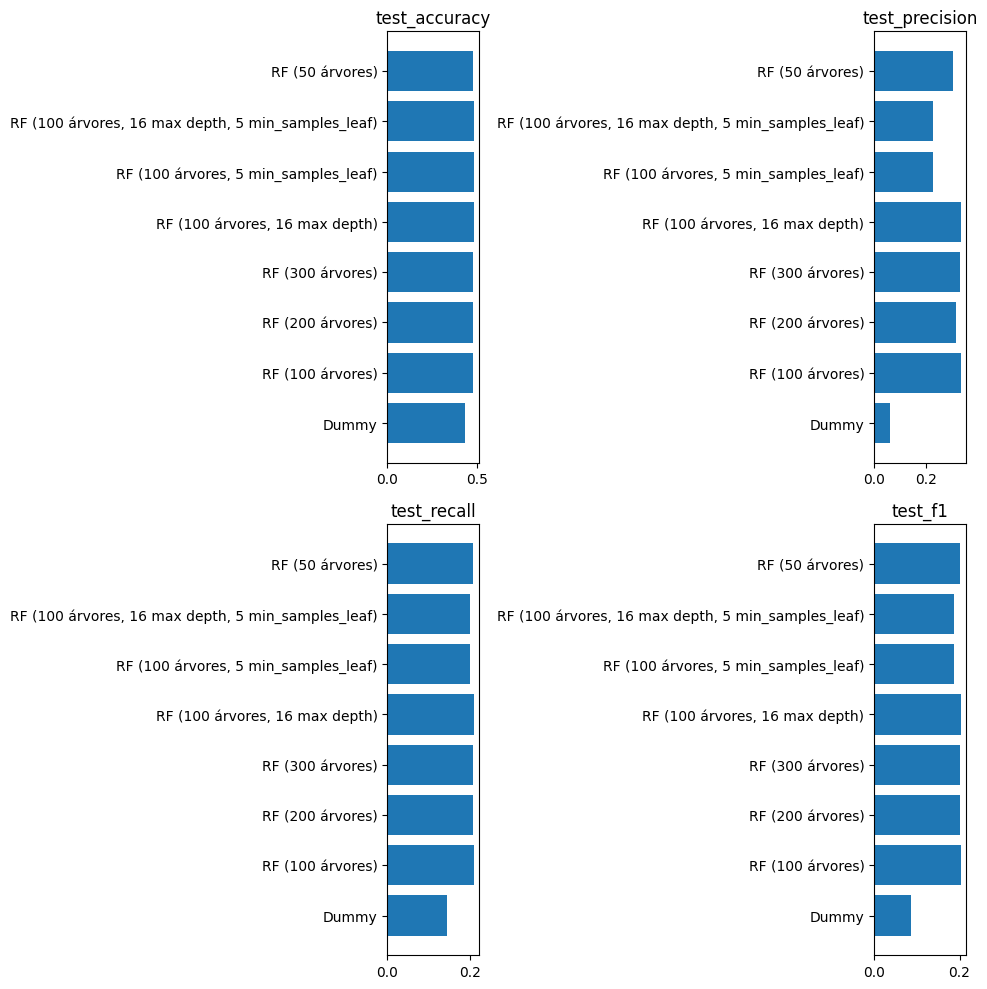

In [9]:
# um gráfico de barra para cada métrica (acurácia, precisão, Sensibilidade, F1 Score) com o desempenho dae cada modelo
import matplotlib.pyplot as plt

metrics = ['test_accuracy', 'test_precision', 'test_recall', 'test_f1']

fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for i, metric in enumerate(metrics):
    row, col = i // 2, i % 2
    axs[row, col].barh(results_df.index, results_df[metric], label=metric)
    axs[row, col].set_title(metric)

plt.tight_layout()
plt.show()


## Outros modelos de floresta

O Random Forest é apenas uma das várias famílias de modelos baseados em conjuntos de árvores. A diferença entre elas está principalmente em **como as árvores são geradas**, **como a aleatoriedade é introduzida** e **como as previsões são combinadas**: por agregação paralela (*bagging*) ou por correção sequencial de erros (*boosting*).

### Extra Trees

O **Extra Trees** (*Extremely Randomized Trees*) é o parente mais próximo do Random Forest. Assim como este, treina várias árvores independentes e agrega suas previsões. A diferença decisiva está no ponto de corte: em vez de procurar o melhor limiar para cada variável candidata, o Extra Trees sorteia limiares aleatórios e escolhe o melhor entre eles.
Essa aleatoriedade adicional costuma reduzir ainda mais a variância, ao custo de um pequeno aumento no viés.

Em termos práticos, o Extra Trees pode ser mais rápido e produzir árvores mais diversificadas, mas nem sempre supera o Random Forest em precisão. A escolha entre ambos deve ser feita por validação cruzada no problema específico.

### Gradient Boosting

O **Gradient Boosting** também constrói uma floresta, mas de maneira **sequencial**. Cada nova árvore não tenta prever diretamente o alvo: ela aprende a corrigir os erros deixados pelo conjunto de árvores anterior.

Enquanto o Random Forest busca principalmente reduzir a variância, o gradient boosting busca reduzir o viés, corrigindo iterativamente padrões ainda não capturados. Isso frequentemente resulta em maior acurácia, mas também torna o método mais sensível a hiperparâmetros como taxa de aprendizado, profundidade das árvores, número de estimadores e regularização.

### XGBoost, LightGBM e CatBoost

XGBoost, LightGBM e CatBoost são implementações modernas de gradient boosting, projetadas para dados tabulares de grande escala. Todas mantêm a ideia de árvores sequenciais que corrigem erros anteriores, mas acrescentam regularização, tratamento eficiente de valores ausentes e otimizações computacionais.

O **XGBoost** introduz um objetivo regularizado, penalizando árvores excessivamente complexas e ajudando a controlar o sobreajuste.

O **LightGBM** utiliza histogramas para discretizar variáveis contínuas, amostragem baseada em gradientes e crescimento do tipo *leaf-wise*, no qual o nó com maior ganho é dividido primeiro; isso acelera o treino, mas pode favorecer sobreajuste em conjuntos pequenos.

O **CatBoost** se destaca pelo tratamento nativo de variáveis categóricas e por técnicas de ordenação que reduzem o vazamento de informações durante o treinamento. Em muitos problemas tabulares, essas implementações superam o Random Forest em desempenho preditivo, porém exigem mais cuidado na validação e no ajuste de hiperparâmetros.

### Isolation Forest

O **Isolation Forest** é diferente dos demais: ele não é usado para classificação nem regressão, mas para **detecção de anomalias**. Em vez de aprender fronteiras que separam classes, suas “árvores de isolamento” particionam aleatoriamente os dados, escolhendo uma variável aleatória e um valor de corte aleatório entre seus valores mínimo e máximo.

A lógica é que anomalias são raras e distintas, portanto tendem a ser isoladas em poucas divisões. O comprimento médio do caminho da raiz até a folha, calculado sobre várias árvores, serve como escore de anomalia: caminhos curtos indicam maior probabilidade de anomalia.

### Quando escolher cada método

- Escolha **Random Forest** quando buscar um modelo robusto, de configuração simples e bom ponto de partida para classificação ou regressão tabular.
- Escolha **Extra Trees** quando quiser maior aleatoriedade, possível ganho de velocidade e árvores mais diversificadas, testando sempre contra o Random Forest.
- Escolha **Gradient Boosting**, especialmente XGBoost, LightGBM ou CatBoost, quando o objetivo for maximizar desempenho em dados tabulares e houver tempo para ajustar hiperparâmetros.
- Escolha **Isolation Forest** quando o problema for identificar observações anômalas, e não prever um rótulo ou valor contínuo.


## Referências

AI Garden. **Types of Bagging Ensemble Methods**. Disponível em https://www.chintan.us/model/ensemble/bagging-types/.

Breiman, L. **Random Forests**. Machine Learning 45, 5–32 (2001). https://doi.org/10.1023/A:1010933404324

Enginners of AI. **Ensemble Methods**: Why Combining Models Beats Every Individual One. Disponível em https://engineersofai.com/docs/break-into-ai/ml-fundamentals/ensemble-methods.

Google For Developers. **Florestas Aleatórias**. Disponível https://developers.google.com/machine-learning/decision-forests/random-forests?hl=pt-br.

Kavlakoglu, Eda. **What is random forest?**. Disponível em https://www.ibm.com/think/topics/random-forest.

Llamas, Luis. **Bagging and Random Forest**: How They Work. Disponível em https://www.luisllamas.es/en/bagging-random-forest-ensemble-learning/.

Scikit-learn. **IsolationForest**. Disponível em https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html#sklearn.ensemble.IsolationForest.

Scikit-learn. **RandomForestClassifier**. Disponível em https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html.

Scikit-learn. **1.11. Ensembles: Gradient boosting, random forests, bagging, voting, stacking**. Disponível em https://scikit-learn.org/stable/modules/ensemble.html#random-forests-and-other-randomized-tree-ensembles.

XGBoost. **Introduction to Boosted Trees**. Disponível em https://xgboost.readthedocs.io/en/stable/tutorials/model.html.